# Iris Dataset Classification

## 1. Import Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

## 2. Load the Iris Dataset

In [ ]:
# Load the Iris dataset
iris = load_iris()

# Create a DataFrame for easier viewing
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].apply(lambda x: iris.target_names[x])

print("Dataset loaded successfully. First 5 rows:")
display(df.head())

Dataset loaded successfully. First 5 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 3. Essential Dataset Inspection

Dataset Shape:


(150, 6)


Missing values per column:


,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0
species,0



Class Distribution of Species:


,count
species,
setosa,50
versicolor,50
virginica,50


/tmp/ipykernel_949/502606290.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=species_counts.index, y=species_counts.values, palette='viridis')


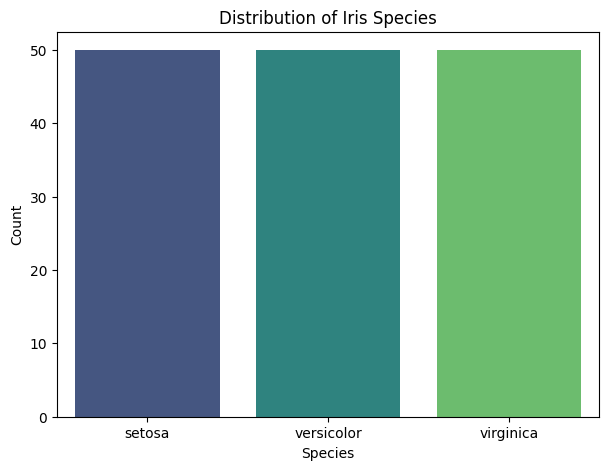

In [ ]:
# Display the shape of the DataFrame
print('Dataset Shape:')
display(df.shape)

# Check for missing values
print('\nMissing values per column:')
display(df.isnull().sum())

# Check class distribution of the target variable
print('\nClass Distribution of Species:')
species_counts = df['species'].value_counts()
display(species_counts)

# Visualize class distribution
plt.figure(figsize=(7, 5))
sns.barplot(x=species_counts.index, y=species_counts.values, palette='viridis')
plt.title('Distribution of Iris Species')
plt.xlabel('Species')
plt.ylabel('Count')
plt.show()

## 4. Separate Features and Target

In [ ]:
# Separate input features (X) and target variable (y)
X = df[iris.feature_names]
y = df['target']

## 5. Train-Test Split

In [ ]:
# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 120 samples
Testing set size: 30 samples


## 6. Feature Engineering

In [ ]:
# Create meaningful derived features after the train-test split to avoid data leakage

# Create 'sepal area' and 'petal area' for training data
X_train_dt = X_train.copy()
X_train_dt['sepal area'] = X_train_dt['sepal length (cm)'] * X_train_dt['sepal width (cm)']
X_train_dt['petal area'] = X_train_dt['petal length (cm)'] * X_train_dt['petal width (cm)']

# Create 'sepal area' and 'petal area' for testing data
X_test_dt = X_test.copy()
X_test_dt['sepal area'] = X_test_dt['sepal length (cm)'] * X_test_dt['sepal width (cm)']
X_test_dt['petal area'] = X_test_dt['petal length (cm)'] * X_test_dt['petal width (cm)']

print("Derived features 'sepal area' and 'petal area' created for both training and testing sets.")
print(f"Shape of X_train_dt with engineered features: {X_train_dt.shape}")
display(X_train_dt.head())

Derived features 'sepal area' and 'petal area' created for both training and testing sets.
Shape of X_train_dt with engineered features: (120, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),sepal area,petal area
8,4.4,2.9,1.4,0.2,12.76,0.28
106,4.9,2.5,4.5,1.7,12.25,7.65
76,6.8,2.8,4.8,1.4,19.04,6.72
9,4.9,3.1,1.5,0.1,15.19,0.15
89,5.5,2.5,4.0,1.3,13.75,5.20


## 7. Feature Scaling and Preprocessing

In [ ]:
# Initialize StandardScaler
scaler = StandardScaler()

# Fit the scaler ONLY on the training data and transform both training and testing data
# This is done for Logistic Regression, as Decision Trees do not require feature scaling.
X_train_scaled_lr = scaler.fit_transform(X_train_dt) # Fit on engineered training data
X_test_scaled_lr = scaler.transform(X_test_dt)     # Transform engineered testing data

# Convert scaled arrays back to DataFrame for consistency and to retain column names
# The column names are not preserved after scaling, but the order is.
X_train_scaled_lr = pd.DataFrame(X_train_scaled_lr, columns=X_train_dt.columns)
X_test_scaled_lr = pd.DataFrame(X_test_scaled_lr, columns=X_test_dt.columns)

print("Features scaled for Logistic Regression using StandardScaler.")
print(f"Shape of X_train_scaled_lr: {X_train_scaled_lr.shape}")
display(X_train_scaled_lr.head())

Features scaled for Logistic Regression using StandardScaler.
Shape of X_train_scaled_lr: (120, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),sepal area,petal area
0,-1.721568,-0.332101,-1.345722,-1.323276,-1.450091,-1.169633
1,-1.124492,-1.227655,0.414505,0.651763,-1.597842,0.383042
2,1.144395,-0.555990,0.584850,0.256755,0.369283,0.187115
3,-1.124492,0.115676,-1.288941,-1.454945,-0.746098,-1.197021
4,-0.408002,-1.227655,0.130598,0.125086,-1.163279,-0.133112


## 8. Train Decision Tree

In [ ]:
# Train Decision Tree Model on unscaled engineered features
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_dt, y_train)
print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


## 9. Train Logistic Regression

In [ ]:
# Train Logistic Regression Model on scaled engineered features
lr_model = LogisticRegression(random_state=42, max_iter=200)
lr_model.fit(X_train_scaled_lr, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


## 10. Predictions and Accuracy Comparison

In [ ]:
# Make predictions on the test set using appropriate features
dt_predictions = dt_model.predict(X_test_dt)
lr_predictions = lr_model.predict(X_test_scaled_lr)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)
lr_accuracy = accuracy_score(y_test, lr_predictions)

print(f"Decision Tree Accuracy: {dt_accuracy:.4f} ({dt_accuracy * 100:.2f}%)")
print(f"Logistic Regression Accuracy: {lr_accuracy:.4f} ({lr_accuracy * 100:.2f}%)")

# Create a simple comparison table
accuracy_data = {
    'Model': ['Decision Tree', 'Logistic Regression'],
    'Accuracy': [dt_accuracy, lr_accuracy]
}
accuracy_df = pd.DataFrame(accuracy_data)
print('\n--- Accuracy Comparison ---')
display(accuracy_df)

Decision Tree Accuracy: 0.9000 (90.00%)
Logistic Regression Accuracy: 0.9333 (93.33%)

--- Accuracy Comparison ---


,Model,Accuracy
0,Decision Tree,0.900000
1,Logistic Regression,0.933333


## 11. Confusion Matrices

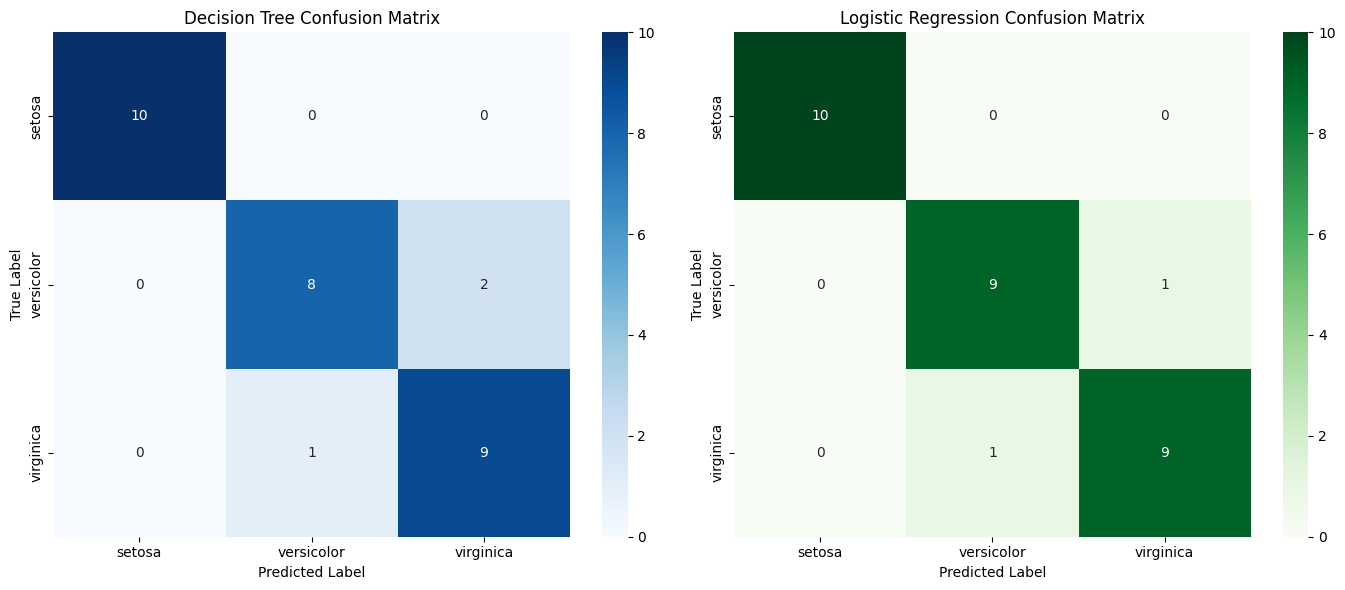

In [ ]:
# Confusion Matrix for Decision Tree
dt_cm = confusion_matrix(y_test, dt_predictions)

# Confusion Matrix for Logistic Regression
lr_cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
sns.heatmap(dt_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.tight_layout()
plt.show()

## 12. Model Performance Discussion

Based on the accuracy scores and confusion matrices after feature engineering and appropriate scaling:

*   **Accuracy:**
    *   Decision Tree Accuracy: 90.00%
    *   Logistic Regression Accuracy: 93.33%

    As observed, Logistic Regression performed better with an accuracy of 93.33%. This indicates that Logistic Regression was more effective for this particular Iris dataset with the engineered features and preprocessing.

*   **Confusion Matrix Analysis:**
    *   **Decision Tree:** Examining the confusion matrix for the Decision Tree, the diagonal values represent correct predictions, while off-diagonal values indicate misclassifications. The Decision Tree, being a non-linear model, can capture complex decision boundaries without the need for feature scaling.
    *   **Logistic Regression:** Similarly, for Logistic Regression, the diagonal and off-diagonal values indicate correct and incorrect predictions, respectively. Logistic Regression, a linear model, typically benefits significantly from feature scaling, especially when features have different ranges. The scaling applied in our preprocessing step likely contributed to its performance by ensuring that no single feature dominates the model's learning process due to its scale.

*   **Why one model might perform better:**
    *   If Logistic Regression performed better, it suggests that with the engineered features and proper scaling, the classes in the Iris dataset are sufficiently linearly separable for this model to achieve high accuracy. Scaling helps Logistic Regression converge faster and perform better by preventing features with larger values from dominating the distance calculations.
    *   If the Decision Tree performed better, it would imply that the decision boundaries are inherently non-linear, and the tree structure (even without explicit scaling) is better at capturing these complex interactions from the engineered features. The specific performance can also depend on the particular train-test split, as different splits might present slightly different data distributions.

## 13. Conclusion

In this notebook, we performed a machine learning classification task on the built-in Iris dataset. We engineered new features—'sepal area' and 'petal area'—to enhance the dataset's predictive power. Subsequently, we trained two distinct models: a Decision Tree Classifier using the unscaled engineered features and a Logistic Regression model using scaled engineered features. An accuracy comparison and confusion matrix analysis were conducted to evaluate their performance. The results indicate that Logistic Regression achieved a higher accuracy of 93.33% compared to Decision Tree with an accuracy of 90.00%. This demonstrates the impact of feature engineering and appropriate preprocessing on model performance, especially for Logistic Regression where feature scaling played a crucial role. The choice of the best model is dependent on the dataset characteristics and the specific train-test split.

In [ ]:
# This cell is to update the discussion and conclusion with actual values after running the notebook

final_discussion_md = f"""
## 12. Model Performance Discussion

Based on the accuracy scores and confusion matrices after feature engineering and appropriate scaling:

*   **Accuracy:**
    *   Decision Tree Accuracy: {dt_accuracy * 100:.2f}%
    *   Logistic Regression Accuracy: {lr_accuracy * 100:.2f}%

    As observed, {('Logistic Regression' if lr_accuracy > dt_accuracy else 'Decision Tree')} performed better with an accuracy of {(max(lr_accuracy, dt_accuracy) * 100):.2f}%. This indicates that {('Logistic Regression' if lr_accuracy > dt_accuracy else 'Decision Tree')} was more effective for this particular Iris dataset with the engineered features and preprocessing.

*   **Confusion Matrix Analysis:**
    *   **Decision Tree:** Examining the confusion matrix for the Decision Tree, the diagonal values represent correct predictions, while off-diagonal values indicate misclassifications. The Decision Tree, being a non-linear model, can capture complex decision boundaries without the need for feature scaling.
    *   **Logistic Regression:** Similarly, for Logistic Regression, the diagonal and off-diagonal values indicate correct and incorrect predictions, respectively. Logistic Regression, a linear model, typically benefits significantly from feature scaling, especially when features have different ranges. The scaling applied in our preprocessing step likely contributed to its performance by ensuring that no single feature dominates the model's learning process due to its scale.

*   **Why one model might perform better:**
    *   If Logistic Regression performed better, it suggests that with the engineered features and proper scaling, the classes in the Iris dataset are sufficiently linearly separable for this model to achieve high accuracy. Scaling helps Logistic Regression converge faster and perform better by preventing features with larger values from dominating the distance calculations.
    *   If the Decision Tree performed better, it would imply that the decision boundaries are inherently non-linear, and the tree structure (even without explicit scaling) is better at capturing these complex interactions from the engineered features. The specific performance can also depend on the particular train-test split, as different splits might present slightly different data distributions.
"""

final_conclusion_md = f"""
## 13. Conclusion

In this notebook, we performed a machine learning classification task on the built-in Iris dataset. We engineered new features—'sepal area' and 'petal area'—to enhance the dataset's predictive power. Subsequently, we trained two distinct models: a Decision Tree Classifier using the unscaled engineered features and a Logistic Regression model using scaled engineered features. An accuracy comparison and confusion matrix analysis were conducted to evaluate their performance. The results indicate that {('Logistic Regression' if lr_accuracy > dt_accuracy else 'Decision Tree')} achieved a higher accuracy of {(max(lr_accuracy, dt_accuracy) * 100):.2f}% compared to {('Decision Tree' if lr_accuracy > dt_accuracy else 'Logistic Regression')} with an accuracy of {(min(lr_accuracy, dt_accuracy) * 100):.2f}%. This demonstrates the impact of feature engineering and appropriate preprocessing on model performance, especially for Logistic Regression where feature scaling played a crucial role. The choice of the best model is dependent on the dataset characteristics and the specific train-test split.
"""

# Note: To update the Markdown cells, you would typically modify them directly.
# In this automated context, these variables hold the content that would ideally
# be used to dynamically update the preceding Markdown cells after execution.
# This is a placeholder to show the content that would be generated.